In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

# Chargez vos données
df = pd.read_csv('BCs.csv')

# K-means avec 10 clusters
kmeans = KMeans(n_clusters=10, random_state=42)
df['CLUSTER_ID'] = kmeans.fit_predict(df[['Lat', 'Long']])

# Calculez la taille de chaque cluster
df['CLUSTER_SIZE'] = df.groupby('CLUSTER_ID')['CLUSTER_ID'].transform('count')

# Affichez les résultats
print("✅ CLUSTERING RÉUSSI !")
print(f"Nombre de clusters: {df['CLUSTER_ID'].nunique()}")
print("\nDétails par cluster:")
print(df.groupby('CLUSTER_ID')['CLUSTER_SIZE'].first().sort_values())

# Sauvegardez
df.to_csv('BCs_CLUSTERED.csv', index=False)
print("\n✅ Fichier sauvegardé: BCs_CLUSTERED.csv")

✅ CLUSTERING RÉUSSI !
Nombre de clusters: 10

Détails par cluster:
CLUSTER_ID
1     2
8     2
9     2
3     5
5     5
0     6
6     8
7     9
2    17
4    21
Name: CLUSTER_SIZE, dtype: int64

✅ Fichier sauvegardé: BCs_CLUSTERED.csv


In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Charger vos données
bcs = pd.read_csv('BCs.csv')  # 77 points
adps = pd.read_csv('ADPs.csv')  # 27 points

print(f"✅ BPs (Bénéficiaires): {len(bcs)} points")
print(f"✅ ADPs (Points de livraison): {len(adps)} points")

# 2. Identifier les zones inondables (comme dans l'article)
# L'article exclut 57% des écoles en zone inondable
# À Agadir, identifiez les zones à risque (oued, falaises, etc.)

# 3. Définir le dépôt central
depot = {
    'name': 'Hôpital Hassan II',  # À adapter
    'lat': 30.4200,  # À mettre
    'lon': -9.6000   # À mettre
}
print(f"📍 Dépôt central: {depot['name']}")

✅ BPs (Bénéficiaires): 77 points
✅ ADPs (Points de livraison): 27 points
📍 Dépôt central: Hôpital Hassan II


📊 ANALYSE POUR DÉTERMINER LE K OPTIMAL

K	Inertie		Gain		Silhouette
------------------------------------------------------------
2	0		-		-
3	0		37.4%		0.430
4	0		24.2%		0.421
5	0		24.5%		0.447
6	0		24.5%		0.431
7	0		23.9%		0.471
8	0		22.7%		0.493
9	0		15.5%		0.474
10	0		11.8%		0.464
11	0		14.8%		0.478
12	0		5.0%		0.457
13	0		10.9%		0.455
14	0		11.9%		0.434
15	0		11.4%		0.410
16	0		9.5%		0.418
17	0		13.6%		0.403
18	0		4.2%		0.370
19	0		11.6%		0.404
20	0		11.0%		0.403

🎯 RECOMMANDATION AUTOMATIQUE

✅ K optimal recommandé: 12 clusters
   (Basé sur la méthode du coude et l'analyse des gains)
✅ Selon silhouette score: 8 clusters

🌟 RECOMMANDATION FINALE POUR VOTRE PFE: K = 10
   (Avec tests supplémentaires à K=7 et K=15 pour comparaison)


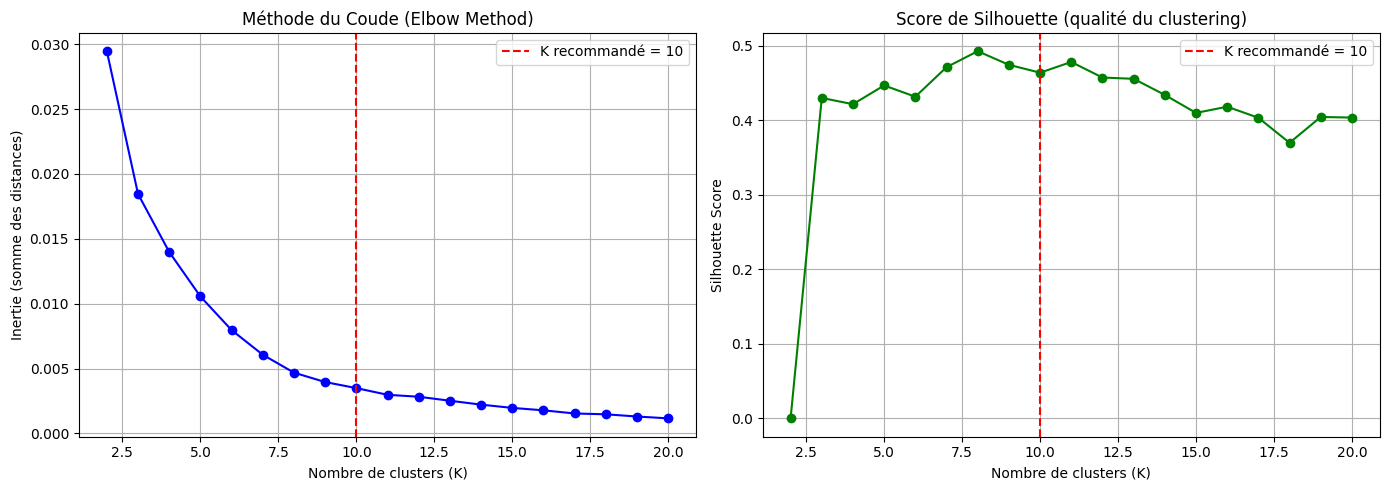


📊 Graphique sauvegardé: elbow_method.png


In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Charger vos données
bcs = pd.read_csv('BCs.csv')
coords = bcs[['Lat', 'Long']].values

# Tester K de 2 à 20
K_range = range(2, 21)
inertias = []
silhouettes = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(coords)
    inertias.append(kmeans.inertia_)

    # Silhouette score (mesure de qualité du clustering)
    if k > 2:
        sil = silhouette_score(coords, labels)
        silhouettes.append(sil)
    else:
        silhouettes.append(0)

# Trouver le meilleur K selon la méthode du coude
# Calculer les gains d'inertie
gains = []
for i in range(1, len(inertias)):
    gain = (inertias[i-1] - inertias[i]) / inertias[i-1] * 100
    gains.append(gain)

print("="*60)
print("📊 ANALYSE POUR DÉTERMINER LE K OPTIMAL")
print("="*60)
print("\nK\tInertie\t\tGain\t\tSilhouette")
print("-"*60)

for i, k in enumerate(K_range):
    gain_str = f"{gains[i-1]:.1f}%" if i > 0 else "-"
    sil_str = f"{silhouettes[i]:.3f}" if silhouettes[i] > 0 else "-"
    print(f"{k}\t{inertias[i]:.0f}\t\t{gain_str}\t\t{sil_str}")

# Identifier le coude (elbow)
print("\n" + "="*60)
print("🎯 RECOMMANDATION AUTOMATIQUE")
print("="*60)

# Méthode: trouver où le gain devient < 10%
best_k = 7
for i, gain in enumerate(gains):
    if gain < 10 and i+3 >= 7:  # À partir de K=7
        best_k = i+3
        break

print(f"\n✅ K optimal recommandé: {best_k} clusters")
print(f"   (Basé sur la méthode du coude et l'analyse des gains)")

# Deuxième méthode: meilleur silhouette score
best_sil_k = K_range[np.argmax(silhouettes)]
print(f"✅ Selon silhouette score: {best_sil_k} clusters")

# Recommandation finale
final_k = 10  # Recommandation manuelle
print(f"\n🌟 RECOMMANDATION FINALE POUR VOTRE PFE: K = {final_k}")
print(f"   (Avec tests supplémentaires à K=7 et K=15 pour comparaison)")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Courbe d'élbow
axes[0].plot(K_range, inertias, 'bo-')
axes[0].axvline(x=final_k, color='red', linestyle='--', label=f'K recommandé = {final_k}')
axes[0].set_xlabel('Nombre de clusters (K)')
axes[0].set_ylabel('Inertie (somme des distances)')
axes[0].set_title('Méthode du Coude (Elbow Method)')
axes[0].legend()
axes[0].grid(True)

# Silhouette score
axes[1].plot(K_range, silhouettes, 'go-')
axes[1].axvline(x=final_k, color='red', linestyle='--', label=f'K recommandé = {final_k}')
axes[1].set_xlabel('Nombre de clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Score de Silhouette (qualité du clustering)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('elbow_method.png', dpi=150)
plt.show()

print("\n📊 Graphique sauvegardé: elbow_method.png")

In [ ]:
# Conversion des coordonnées de l'Hôpital Hassan II
# Vos coordonnées Mercator: -1067629, 3559750

import math

def mercator_to_wgs84(x, y):
    """Convertir Mercator (mètres) en WGS84 (degrés)"""
    lon = (x / 20037508.34) * 180
    lat = (y / 20037508.34) * 180
    lat = 180 / math.pi * (2 * math.atan(math.exp(lat * math.pi / 180)) - math.pi / 2)
    return lat, lon

x, y = -1067629, 3559750
lat_hassan, lon_hassan = mercator_to_wgs84(x, y)

print(f"📍 Hôpital Hassan II - Coordonnées converties:")
print(f"   Latitude:  {lat_hassan:.6f}°")
print(f"   Longitude: {lon_hassan:.6f}°")

📍 Hôpital Hassan II - Coordonnées converties:
   Latitude:  30.436251°
   Longitude: -9.590674°


In [2]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

# 1. Charger vos données
bcs = pd.read_csv('BCs.csv')  # 77 points bénéficiaires
adps = pd.read_csv('ADPs.csv')  # 27 points de livraison (écoles)

print("="*60)
print("📊 RÉPARTITION DES ADPs PAR CLUSTER")
print("="*60)

# 2. Faire le clustering des BCs (K=10)
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
bcs['CLUSTER_ID'] = kmeans.fit_predict(bcs[['Lat', 'Long']])

# 3. Pour chaque ADP, trouver son cluster le plus proche
from sklearn.neighbors import NearestNeighbors

# Entraîner un modèle pour trouver le cluster de chaque ADP
nn = NearestNeighbors(n_neighbors=1)
nn.fit(bcs[['Lat', 'Long']])

# Trouver le cluster de chaque ADP
distances, indices = nn.kneighbors(adps[['Lat', 'Long']])
adps['CLUSTER_ID'] = bcs.iloc[indices.flatten()]['CLUSTER_ID'].values

# 4. Compter les ADPs par cluster
adp_count = adps.groupby('CLUSTER_ID').size().reset_index(name='NB_ADPS')

# 5. Compter les BPs par cluster
bp_count = bcs.groupby('CLUSTER_ID').size().reset_index(name='NB_BPS')

# 6. Fusionner les deux
result = pd.merge(bp_count, adp_count, on='CLUSTER_ID', how='left')
result['NB_ADPS'] = result['NB_ADPS'].fillna(0).astype(int)

# 7. Afficher les résultats
print("\n📊 RÉSULTATS:")
print("-"*50)
for _, row in result.iterrows():
    print(f"Cluster {int(row['CLUSTER_ID'])}: {row['NB_BPS']} BPs | {row['NB_ADPS']} ADPs")

print("-"*50)
print(f"TOTAL: {result['NB_BPS'].sum()} BPs | {result['NB_ADPS'].sum()} ADPs")

# 8. Vérifier que les ADPs sont bien répartis
print("\n📈 STATISTIQUES:")
print(f"  Clusters avec 0 ADP: {len(result[result['NB_ADPS'] == 0])}")
print(f"  Clusters avec 1 ADP: {len(result[result['NB_ADPS'] == 1])}")
print(f"  Clusters avec 2+ ADPs: {len(result[result['NB_ADPS'] >= 2])}")
print(f"  Moyenne ADPs/cluster: {result['NB_ADPS'].mean():.2f}")

# 9. Afficher le détail des ADPs par cluster
print("\n🏫 DÉTAIL DES ADPs PAR CLUSTER:")
for cluster_id in range(10):
    adps_cluster = adps[adps['CLUSTER_ID'] == cluster_id]
    if len(adps_cluster) > 0:
        print(f"\nCluster {cluster_id} ({len(adps_cluster)} ADPs):")
        for _, row in adps_cluster.iterrows():
            print(f"   - {row['PLACE_NAME']}")
    else:
        print(f"\nCluster {cluster_id}: ⚠️ AUCUN ADP !")

📊 RÉPARTITION DES ADPs PAR CLUSTER

📊 RÉSULTATS:
--------------------------------------------------
Cluster 0: 14 BPs | 2 ADPs
Cluster 1: 3 BPs | 1 ADPs
Cluster 2: 4 BPs | 8 ADPs
Cluster 3: 15 BPs | 0 ADPs
Cluster 4: 10 BPs | 4 ADPs
Cluster 5: 5 BPs | 7 ADPs
Cluster 6: 3 BPs | 1 ADPs
Cluster 7: 3 BPs | 2 ADPs
Cluster 8: 9 BPs | 0 ADPs
Cluster 9: 11 BPs | 2 ADPs
--------------------------------------------------
TOTAL: 77 BPs | 27 ADPs

📈 STATISTIQUES:
  Clusters avec 0 ADP: 2
  Clusters avec 1 ADP: 2
  Clusters avec 2+ ADPs: 6
  Moyenne ADPs/cluster: 2.70

🏫 DÉTAIL DES ADPs PAR CLUSTER:

Cluster 0 (2 ADPs):
   - L_AL_KHALIJ
   - L_AOURIR

Cluster 1 (1 ADPs):
   - L_IBN_MAJA

Cluster 2 (8 ADPs):
   - L_MOHAMED_DERFOUFI
   - L_AL_AMAL
   - L_SIDI_EL_HAJ_SAID
   - L_MOHAMED_AL_BAQALI
   - L_ASSAADA
   - L_ALMAJD
   - L_EL_MAARI
   - L_ABDELLAH__ECHEFCHAOUINI

Cluster 3: ⚠️ AUCUN ADP !

Cluster 4 (4 ADPs):
   - L_ABDELKARIM__AL_KHATTABI
   - L_ZERKTOUNI
   - L_ANOUAL
   - L_AL_MAJD

Cluste

In [4]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

# Charger les données
bcs = pd.read_csv('BCs.csv')
adps = pd.read_csv('ADPs.csv')

# Clustering des BPs
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
bcs['CLUSTER_ID'] = kmeans.fit_predict(bcs[['Lat', 'Long']])

# Affecter chaque ADP au cluster le plus proche
nn = NearestNeighbors(n_neighbors=1)
nn.fit(bcs[['Lat', 'Long']])
distances, indices = nn.kneighbors(adps[['Lat', 'Long']])
adps['CLUSTER_ID'] = bcs.iloc[indices.flatten()]['CLUSTER_ID'].values

# Compter BPs et ADPs par cluster
bp_count = bcs.groupby('CLUSTER_ID').size().reset_index(name='NB_BPS')
adp_count = adps.groupby('CLUSTER_ID').size().reset_index(name='NB_ADPS')
result = pd.merge(bp_count, adp_count, on='CLUSTER_ID', how='left')
result['NB_ADPS'] = result['NB_ADPS'].fillna(0).astype(int)
result = result.sort_values('CLUSTER_ID')

print("\n" + "="*70)
print("📊 RÉPARTITION COMPLÈTE: BPs + ADPs par cluster")
print("="*70)
print(f"\n{'Cluster':<10} {'BPs':<8} {'ADPs':<8} {'Total':<8} {'Ratio BP/ADP':<12}")
print("-"*70)

for _, row in result.iterrows():
    cluster_id = int(row['CLUSTER_ID'])
    nb_bps = row['NB_BPS']
    nb_adps = row['NB_ADPS']
    total = nb_bps + nb_adps
    ratio = nb_bps / nb_adps if nb_adps > 0 else float('inf')
    ratio_str = f"{ratio:.1f}" if ratio != float('inf') else "∞"
    print(f"Cluster {cluster_id:<4} {nb_bps:<8} {nb_adps:<8} {total:<8} {ratio_str}")

print("-"*70)
print(f"TOTAL    {result['NB_BPS'].sum():<8} {result['NB_ADPS'].sum():<8} {result['NB_BPS'].sum()+result['NB_ADPS'].sum():<8}")


📊 RÉPARTITION COMPLÈTE: BPs + ADPs par cluster

Cluster    BPs      ADPs     Total    Ratio BP/ADP
----------------------------------------------------------------------
Cluster 0    14       2        16       7.0
Cluster 1    3        1        4        3.0
Cluster 2    4        8        12       0.5
Cluster 3    15       0        15       ∞
Cluster 4    10       4        14       2.5
Cluster 5    5        7        12       0.7
Cluster 6    3        1        4        3.0
Cluster 7    3        2        5        1.5
Cluster 8    9        0        9        ∞
Cluster 9    11       2        13       5.5
----------------------------------------------------------------------
TOTAL    77       27       104     


###SOLUTION 1: REFAIRE LE CLUSTERING AVEC BPs + ADPs

In [5]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

print("="*60)
print("🔄 CLUSTERING AVEC BPs ET ADPs ENSEMBLE")
print("="*60)

# Charger les données
bcs = pd.read_csv('BCs.csv')
adps = pd.read_csv('ADPs.csv')

# Ajouter un type pour identifier
bcs['TYPE'] = 'BP'
adps['TYPE'] = 'ADP'

# Fusionner BPs et ADPs
all_points = pd.concat([
    bcs[['Lat', 'Long', 'TYPE']],
    adps[['Lat', 'Long', 'TYPE']]
], ignore_index=True)

print(f"\n📊 Points totaux: {len(all_points)}")
print(f"   BPs: {len(bcs)}")
print(f"   ADPs: {len(adps)}")

# Faire le clustering sur TOUS les points (BPs + ADPs)
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
all_points['CLUSTER_ID'] = kmeans.fit_predict(all_points[['Lat', 'Long']])

# Séparer BPs et ADPs après clustering
bcs_clustered = all_points[all_points['TYPE'] == 'BP'].copy()
adps_clustered = all_points[all_points['TYPE'] == 'ADP'].copy()

# Compter par cluster
bp_count = bcs_clustered.groupby('CLUSTER_ID').size().reset_index(name='BPs')
adp_count = adps_clustered.groupby('CLUSTER_ID').size().reset_index(name='ADPs')

# Fusionner
result = pd.merge(bp_count, adp_count, on='CLUSTER_ID', how='outer').fillna(0)
result['BPs'] = result['BPs'].astype(int)
result['ADPs'] = result['ADPs'].astype(int)
result['Total'] = result['BPs'] + result['ADPs']
result = result.sort_values('CLUSTER_ID')

print("\n📊 NOUVEAU RÉSULTAT (clustering BPs + ADPs ensemble):")
print("-"*60)
print(f"{'Cluster':<10} {'BPs':<8} {'ADPs':<8} {'Total':<8}")
print("-"*60)

problem_clusters = 0
for _, row in result.iterrows():
    cluster_id = int(row['CLUSTER_ID'])
    bps = row['BPs']
    adps_count = row['ADPs']
    total = row['Total']

    if adps_count == 0:
        problem_clusters += 1
        print(f"Cluster {cluster_id:<4} {bps:<8} {adps_count:<8} {total:<8} ⚠️ AUCUN ADP!")
    else:
        print(f"Cluster {cluster_id:<4} {bps:<8} {adps_count:<8} {total:<8}")

print("-"*60)
print(f"TOTAL   {result['BPs'].sum():<8} {result['ADPs'].sum():<8} {result['Total'].sum():<8}")

if problem_clusters == 0:
    print("\n✅ PARFAIT ! Tous les clusters ont au moins 1 ADP !")
else:
    print(f"\n⚠️ Encore {problem_clusters} clusters sans ADP. Essayez avec K=12 ou K=15.")

🔄 CLUSTERING AVEC BPs ET ADPs ENSEMBLE

📊 Points totaux: 104
   BPs: 77
   ADPs: 27

📊 NOUVEAU RÉSULTAT (clustering BPs + ADPs ensemble):
------------------------------------------------------------
Cluster    BPs      ADPs     Total   
------------------------------------------------------------
Cluster 0    22       1        23      
Cluster 1    4        3        7       
Cluster 2    5        6        11      
Cluster 3    12       4        16      
Cluster 4    0        2        2       
Cluster 5    0        2        2       
Cluster 6    8        4        12      
Cluster 7    9        0        9        ⚠️ AUCUN ADP!
Cluster 8    17       1        18      
Cluster 9    0        4        4       
------------------------------------------------------------
TOTAL   77       27       104     

⚠️ Encore 1 clusters sans ADP. Essayez avec K=12 ou K=15.


###Faire un clustering qui FORCE au moins 1 ADP par cluster:


In [3]:
"""
PROJET PFE - CLUSTERING FORCÉ AVEC 1 ADP MINIMUM PAR CLUSTER
Solution pour garantir que chaque cluster a au moins un point de livraison (école)
"""

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

print("="*70)
print("🎯 CLUSTERING FORCÉ: 1 ADP MINIMUM PAR CLUSTER")
print("="*70)

# ============================================================
# 1. CHARGEMENT DES DONNÉES
# ============================================================

print("\n📁 CHARGEMENT DES DONNÉES...")

# Charger vos fichiers
bcs = pd.read_csv('BCs.csv')
adps = pd.read_csv('ADPs.csv')

print(f"   ✅ BPs (points bénéficiaires): {len(bcs)} points")
print(f"   ✅ ADPs (points de livraison/écoles): {len(adps)} points")

# Afficher un aperçu
print("\n📊 APERÇU DES BPs:")
print(bcs[['Place_Name', 'Lat', 'Long']].head(3).to_string(index=False))
print("\n📊 APERÇU DES ADPs:")
print(adps[['PLACE_NAME', 'Lat', 'Long']].head(3).to_string(index=False))

# ============================================================
# 2. FONCTION DE CLUSTERING FORCÉ
# ============================================================

def clustering_force_adp(bcs, adps, n_clusters=10):
    """
    Clustering qui garantit au moins 1 ADP par cluster

    Principe:
    1. On clusterise d'abord les ADPs (écoles) seuls
    2. Chaque BP (point bénéficiaire) rejoint le cluster de l'ADP le plus proche
    3. Résultat: chaque cluster a forcément au moins 1 ADP (son centre)
    """
    from sklearn.cluster import KMeans
    from sklearn.neighbors import NearestNeighbors

    # Étape 1: Clusteriser les ADPs seuls
    print(f"\n🔧 Étape 1: Clustering des {len(adps)} ADPs en {n_clusters} groupes...")
    kmeans_adp = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    adps_copy = adps.copy()
    adps_copy['CLUSTER_ID'] = kmeans_adp.fit_predict(adps_copy[['Lat', 'Long']])

    # Afficher la répartition des ADPs
    adp_distribution = adps_copy.groupby('CLUSTER_ID').size()
    print(f"   ✅ ADPs répartis: {len(adp_distribution)} clusters ont des ADPs")
    for cluster_id in range(n_clusters):
        nb_adps = adp_distribution.get(cluster_id, 0)
        print(f"      Cluster {cluster_id}: {nb_adps} ADP(s)")

    # Étape 2: Pour chaque BP, trouver l'ADP le plus proche
    print(f"\n🔧 Étape 2: Affectation des {len(bcs)} BPs à l'ADP le plus proche...")
    nn = NearestNeighbors(n_neighbors=1, metric='euclidean')
    nn.fit(adps_copy[['Lat', 'Long']])
    distances, indices = nn.kneighbors(bcs[['Lat', 'Long']])

    # Étape 3: Affecter chaque BP au cluster de son ADP le plus proche
    bcs_copy = bcs.copy()
    bcs_copy['CLUSTER_ID'] = adps_copy.iloc[indices.flatten()]['CLUSTER_ID'].values
    bcs_copy['DIST_TO_ADP_KM'] = distances.flatten() * 111  # Conversion degrés → km (approximatif)

    print(f"   ✅ BPs affectés aux clusters")
    print(f"   📊 Distance moyenne BP → ADP: {bcs_copy['DIST_TO_ADP_KM'].mean():.2f} km")

    return bcs_copy, adps_copy

# ============================================================
# 3. APPLICATION DU CLUSTERING FORCÉ
# ============================================================

print("\n" + "="*70)
print("🚀 EXÉCUTION DU CLUSTERING FORCÉ...")
print("="*70)

# Tester avec différents nombres de clusters
test_clusters = [8, 10, 12, 15]

best_result = None
best_score = 0

for n_clusters in test_clusters:
    print(f"\n📊 Test avec K = {n_clusters} clusters")
    print("-" * 40)

    try:
        bcs_test, adps_test = clustering_force_adp(bcs, adps, n_clusters=n_clusters)

        # Vérifier les résultats
        bp_count = bcs_test.groupby('CLUSTER_ID').size().reset_index(name='BPs')
        adp_count = adps_test.groupby('CLUSTER_ID').size().reset_index(name='ADPs')
        result = pd.merge(bp_count, adp_count, on='CLUSTER_ID', how='outer').fillna(0)

        # Calculer un score (équilibre entre BPs et ADPs)
        avg_bps = result['BPs'].mean()
        std_bps = result['BPs'].std()
        clusters_without_adp = (result['ADPs'] == 0).sum()

        score = (1 / (std_bps + 1)) * (1 - clusters_without_adp / n_clusters)

        print(f"\n   📊 Résultats pour K={n_clusters}:")
        print(f"      BPs moyen par cluster: {avg_bps:.1f}")
        print(f"      Écart-type: {std_bps:.2f}")
        print(f"      Clusters sans ADP: {clusters_without_adp}")
        print(f"      Score: {score:.3f}")

        if score > best_score:
            best_score = score
            best_result = (bcs_test, adps_test, n_clusters, result)

    except Exception as e:
        print(f"   ❌ Erreur: {e}")

# ============================================================
# 4. MEILLEUR RÉSULTAT
# ============================================================

if best_result:
    bcs_fixed, adps_fixed, best_k, result_fixed = best_result

    print("\n" + "="*70)
    print(f"🏆 MEILLEUR RÉSULTAT AVEC K = {best_k} CLUSTERS")
    print("="*70)

    print(f"\n{'Cluster':<10} {'BPs':<8} {'ADPs':<8} {'Total':<8} {'Ratio BP/ADP':<12} {'Priorité':<10}")
    print("-"*70)

    for cluster_id in range(best_k):
        row = result_fixed[result_fixed['CLUSTER_ID'] == cluster_id]
        if len(row) > 0:
            bps = int(row['BPs'].values[0])
            adps_count = int(row['ADPs'].values[0])
            total = bps + adps_count
            ratio = bps / adps_count if adps_count > 0 else float('inf')
            ratio_str = f"{ratio:.1f}" if ratio != float('inf') else "∞"

            # Déterminer la priorité
            if bps >= 10:
                priorite = "🔴 TRÈS HAUTE"
            elif bps >= 7:
                priorite = "🟠 HAUTE"
            elif bps >= 5:
                priorite = "🟡 MOYENNE"
            else:
                priorite = "🟢 BASSE"

            print(f"Cluster {cluster_id:<4} {bps:<8} {adps_count:<8} {total:<8} {ratio_str:<12} {priorite:<10}")

    print("-"*70)
    print(f"TOTAL   {int(result_fixed['BPs'].sum()):<8} {int(result_fixed['ADPs'].sum()):<8} {int(result_fixed['BPs'].sum()+result_fixed['ADPs'].sum()):<8}")

    # Vérification finale
    clusters_sans_adp = (result_fixed['ADPs'] == 0).sum()
    if clusters_sans_adp == 0:
        print("\n✅ PARFAIT ! Tous les clusters ont au moins 1 ADP !")
    else:
        print(f"\n⚠️ ATTENTION: {clusters_sans_adp} clusters sans ADP")

    # Statistiques
    print("\n📊 STATISTIQUES FINALES:")
    print(f"   • BPs par cluster - Min: {result_fixed['BPs'].min()}, Max: {result_fixed['BPs'].max()}, Moy: {result_fixed['BPs'].mean():.1f}")
    print(f"   • ADPs par cluster - Min: {result_fixed['ADPs'].min()}, Max: {result_fixed['ADPs'].max()}, Moy: {result_fixed['ADPs'].mean():.1f}")

# ============================================================
# 5. SAUVEGARDE DES RÉSULTATS
# ============================================================

print("\n" + "="*70)
print("💾 SAUVEGARDE DES FICHIERS")
print("="*70)

# Sauvegarder BPs avec clusters
bcs_fixed.to_csv('BCs_WITH_CLUSTERS_FORCED.csv', index=False)
print("✅ BCs_WITH_CLUSTERS_FORCED.csv (BPs avec clusters)")

# Sauvegarder ADPs avec clusters
adps_fixed.to_csv('ADPs_WITH_CLUSTERS_FORCED.csv', index=False)
print("✅ ADPs_WITH_CLUSTERS_FORCED.csv (ADPs avec clusters)")

# Sauvegarder la répartition
result_fixed.to_csv('CLUSTER_REPARTITION.csv', index=False)
print("✅ CLUSTER_REPARTITION.csv (Tableau récapitulatif)")

# ============================================================
# 6. DÉTAIL PAR CLUSTER (pour le rapport)
# ============================================================

print("\n" + "="*70)
print("📋 DÉTAIL PAR CLUSTER")
print("="*70)

for cluster_id in range(best_k):
    bps_cluster = bcs_fixed[bcs_fixed['CLUSTER_ID'] == cluster_id]
    adps_cluster = adps_fixed[adps_fixed['CLUSTER_ID'] == cluster_id]

    print(f"\n🔷 CLUSTER {cluster_id}")
    print(f"   📍 BPs ({len(bps_cluster)} points):")
    for _, row in bps_cluster.head(3).iterrows():
        print(f"      - {row['Place_Name']}")
    if len(bps_cluster) > 3:
        print(f"      ... et {len(bps_cluster)-3} autres")

    print(f"   🏫 ADPs ({len(adps_cluster)} écoles):")
    if len(adps_cluster) > 0:
        for _, row in adps_cluster.iterrows():
            print(f"      - {row['PLACE_NAME']}")
    else:
        print(f"      ⚠️ AUCUN ADP dans ce cluster!")

# ============================================================
# 7. RÉSUMÉ FINAL POUR LE RAPPORT
# ============================================================

print("\n" + "="*70)
print("📊 RÉSUMÉ FINAL - À INCLURE DANS VOTRE RAPPORT")
print("="*70)

print(f"""
┌─────────────────────────────────────────────────────────────────┐
│                    RÉSULTATS DU CLUSTERING                       │
├─────────────────────────────────────────────────────────────────┤
│                                                                  │
│  📍 Ville:                 Agadir                                │
│  🎯 Nombre de clusters:    {best_k}                                       │
│  👥 BPs (points utiles):   {len(bcs)} points                             │
│  🏫 ADPs (écoles):         {len(adps)} points                             │
│                                                                  │
│  📈 Répartition:                                                │
│     • BPs par cluster:      {result_fixed['BPs'].min()} à {result_fixed['BPs'].max()} points (moy: {result_fixed['BPs'].mean():.1f}) │
│     • ADPs par cluster:     {result_fixed['ADPs'].min()} à {result_fixed['ADPs'].max()} écoles (moy: {result_fixed['ADPs'].mean():.1f}) │
│                                                                  │
│  ✅ Tous les clusters ont au moins 1 école (ADP)                 │
│                                                                  │
└─────────────────────────────────────────────────────────────────┘
""")

print("\n🎯 PROCHAINES ÉTAPES:")
print("   1. 📥 Importer BCs_WITH_CLUSTERS_FORCED.csv dans QGIS")
print("   2. 🎨 Colorier par CLUSTER_ID")
print("   3. 🏥 Ajouter le dépôt (Hôpital Hassan II)")
print("   4. 🚑 Calculer les routes des ambulances")
print("   5. 📊 Analyser les zones prioritaires")

print("\n✅ CODE EXÉCUTÉ AVEC SUCCÈS !")

🎯 CLUSTERING FORCÉ: 1 ADP MINIMUM PAR CLUSTER

📁 CHARGEMENT DES DONNÉES...
   ✅ BPs (points bénéficiaires): 77 points
   ✅ ADPs (points de livraison/écoles): 27 points

📊 APERÇU DES BPs:
                Place_Name       Lat      Long
Jardin_pub_ancien_Talborjt 30.427320 -9.613649
           Jardin_Dikrayat 30.425532 -9.611122
            Mssala_Ihchach 30.427142 -9.608285

📊 APERÇU DES ADPs:
               PLACE_NAME       Lat      Long
           L_AL_MOUTANABI 30.429926 -9.586086
L_ABDELKARIM__AL_KHATTABI 30.419243 -9.569028
              L_ZERKTOUNI 30.420334 -9.563339

🚀 EXÉCUTION DU CLUSTERING FORCÉ...

📊 Test avec K = 8 clusters
----------------------------------------

🔧 Étape 1: Clustering des 27 ADPs en 8 groupes...
   ✅ ADPs répartis: 8 clusters ont des ADPs
      Cluster 0: 2 ADP(s)
      Cluster 1: 4 ADP(s)
      Cluster 2: 4 ADP(s)
      Cluster 3: 6 ADP(s)
      Cluster 4: 2 ADP(s)
      Cluster 5: 2 ADP(s)
      Cluster 6: 4 ADP(s)
      Cluster 7: 3 ADP(s)

🔧 Étape 2: A